In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
PROJECT_ROOT = Path.cwd().parent          # notebooks/ -> market-analyzer/
df = pd.read_parquet(PROJECT_ROOT / "data/processed/listings_clean.parquet")
print(f"Shape: {df.shape}")
print(f"Columns: {len(df.columns)}")

Shape: (16558, 94)
Columns: 94


In [2]:
df[["price", "accommodates", "bedrooms", "bathrooms",
    "amenity_count", "distance_to_center_km"]].describe()

,price,accommodates,bedrooms,amenity_count,distance_to_center_km
count,"16,558.00","16,558.00","16,553.00","16,558.00","16,558.00"
mean,"6,321.84",3.73,1.46,33.42,7.53
std,"10,311.44",2.26,1.16,15.28,10.71
min,320.00,1.00,0.00,0.00,0.04
25%,"3,000.00",2.00,1.00,23.00,2.65
50%,"4,469.75",3.00,1.00,34.00,3.76
75%,"6,856.57",4.00,2.00,44.00,6.66
max,"502,353.28",16.00,50.00,97.00,81.19


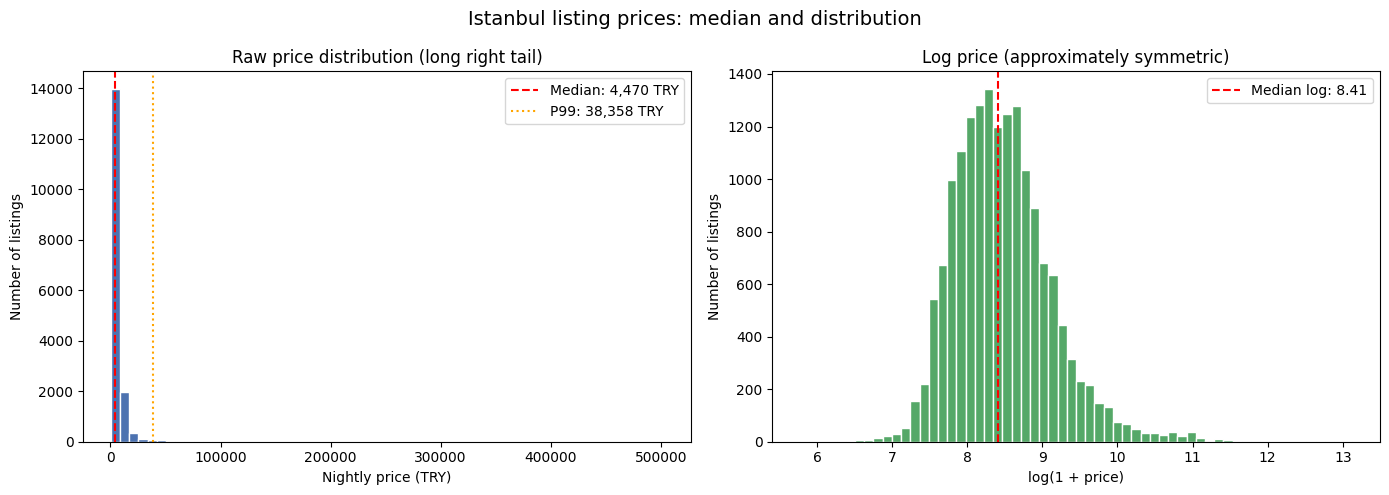

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Left panel: raw price ----
axes[0].hist(df["price"], bins=60, color="#4C72B0", edgecolor="white")
axes[0].axvline(df["price"].median(), color="red", linestyle="--",
                label=f"Median: {df['price'].median():,.0f} TRY")
axes[0].axvline(df["price"].quantile(0.99), color="orange", linestyle=":",
                label=f"P99: {df['price'].quantile(0.99):,.0f} TRY")
axes[0].set_xlabel("Nightly price (TRY)")
axes[0].set_ylabel("Number of listings")
axes[0].set_title("Raw price distribution (long right tail)")
axes[0].legend()

# ---- Right panel: log price ----
axes[1].hist(df["price_log"], bins=60, color="#55A868", edgecolor="white")
axes[1].axvline(df["price_log"].median(), color="red", linestyle="--",
                label=f"Median log: {df['price_log'].median():.2f}")
axes[1].set_xlabel("log(1 + price)")
axes[1].set_ylabel("Number of listings")
axes[1].set_title("Log price (approximately symmetric)")
axes[1].legend()

fig.suptitle("Istanbul listing prices: median and distribution", fontsize=14)
fig.tight_layout()
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent          # notebooks/ -> market-analyzer/
out_path = PROJECT_ROOT / "reports/eda/price_distribution.png"
out_path.parent.mkdir(parents=True, exist_ok=True)   # create reports/eda/ if missing

fig.savefig(out_path, dpi=160, bbox_inches="tight")
plt.show()

In [9]:
print(df['price'].quantile(0.25))


3000.0


In [ ]:
print(df['price'].quantile(0.75))

6856.5675


In [12]:
print(df['price'].max())

502353.28


In [13]:
df.groupby("neighbourhood_cleansed").agg(
    median_price=("price", "median"),
    listings=("listing_id", "count"),
)

,median_price,listings
neighbourhood_cleansed,,
Adalar,"6,688.00",151
Arnavutkoy,"3,444.00",189
Atasehir,"4,737.50",166
Avcilar,"2,300.00",86
Bagcilar,"5,837.00",248
Bahcelievler,"4,364.00",553
Bakirkoy,"4,014.00",144
Basaksehir,"5,485.67",51
Bayrampasa,"5,796.00",18


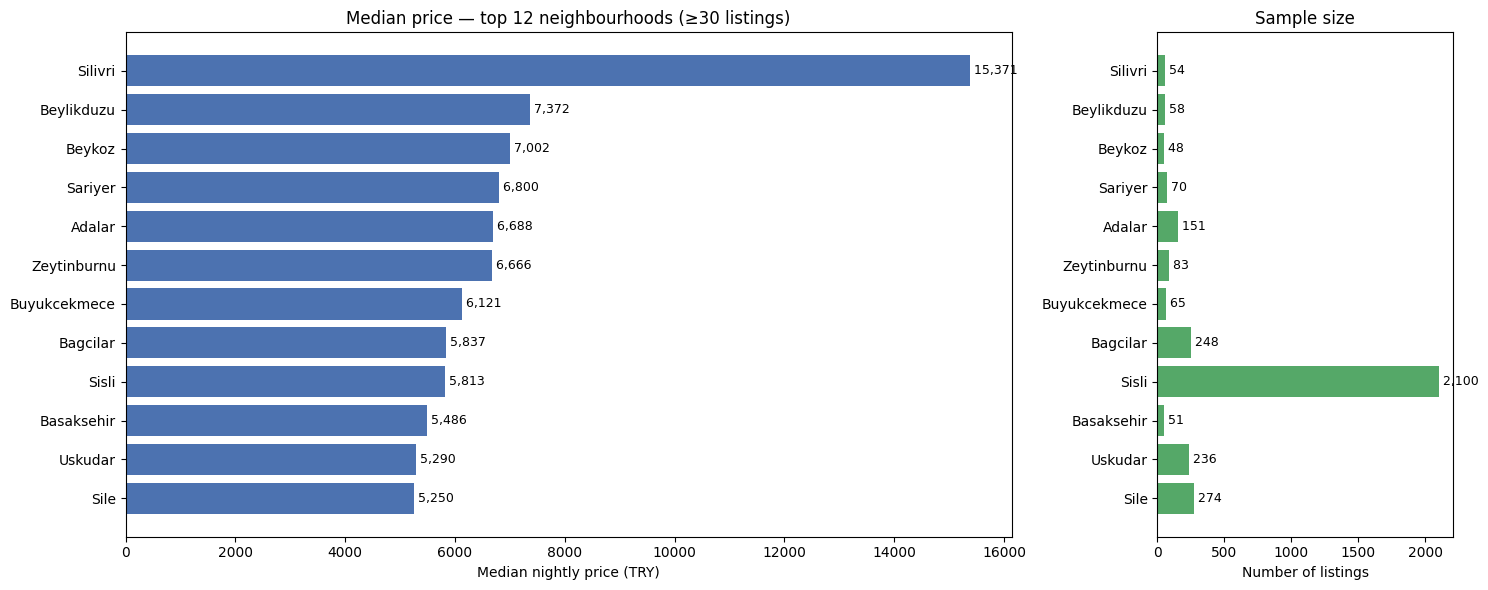

                        median_price  mean_price  listings
neighbourhood_cleansed                                    
Silivri                    15,370.94   32,688.78        54
Beylikduzu                  7,372.50    9,508.76        58
Beykoz                      7,002.50    9,376.12        48
Sariyer                     6,800.00   13,101.74        70
Adalar                      6,688.00    7,959.61       151
Zeytinburnu                 6,666.00    9,114.22        83
Buyukcekmece                6,121.00    9,658.60        65
Bagcilar                    5,837.00    7,489.60       248
Sisli                       5,812.64    7,612.16      2100
Basaksehir                  5,485.67    5,454.27        51
Uskudar                     5,289.90    6,575.30       236
Sile                        5,249.50    7,141.46       274


In [22]:
neighbourhood_summary = (
    df.groupby("neighbourhood_cleansed")
    .agg(
        median_price=("price", "median"),
        listings=("listing_id", "count"),
        mean_price=("price", "mean"),
    )
    .query("listings >= 30")
    .sort_values("median_price", ascending=False)
)

top = neighbourhood_summary.head(12).iloc[::-1]   # reverse for horizontal bar order

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [3, 1]})

# Left: median price bars
axes[0].barh(top.index, top["median_price"], color="#4C72B0")
axes[0].set_xlabel("Median nightly price (TRY)")
axes[0].set_title(f"Median price — top 12 neighbourhoods (≥30 listings)")
for i, v in enumerate(top["median_price"]):
    axes[0].text(v, i, f" {v:,.0f}", va="center", fontsize=9)

# Right: listing counts
axes[1].barh(top.index, top["listings"], color="#55A868")
axes[1].set_xlabel("Number of listings")
axes[1].set_title("Sample size")
for i, v in enumerate(top["listings"]):
    axes[1].text(v, i, f" {v:,}", va="center", fontsize=9)

fig.tight_layout()
out_path = PROJECT_ROOT / "reports/eda/neighbourhood_prices.png"
fig.savefig(out_path, dpi=160, bbox_inches="tight")
plt.show()

# Also print the table for evidence
print(neighbourhood_summary.head(12)[["median_price", "mean_price", "listings"]])

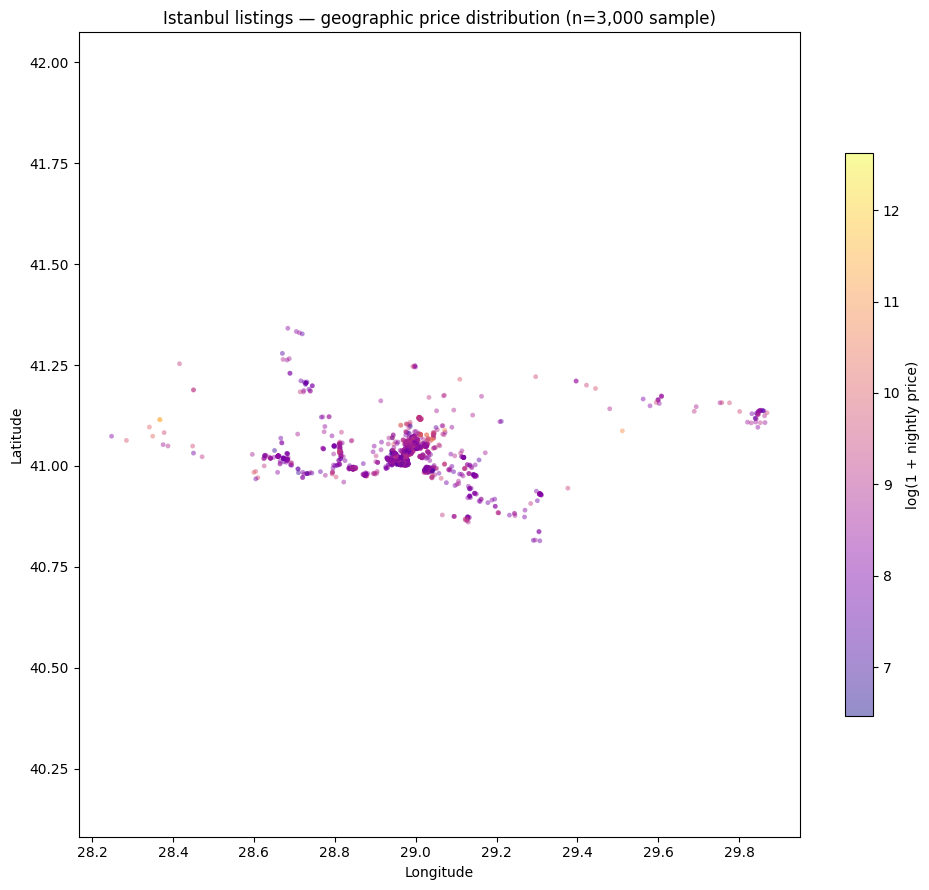

In [19]:
# Sample for readability
sample = df.sample(n=min(3000, len(df)), random_state=42)

fig, ax = plt.subplots(figsize=(10, 9))

sc = ax.scatter(
    sample["longitude"],
    sample["latitude"],
    c=sample["price_log"],
    cmap="plasma",
    alpha=0.45,
    s=12,
    edgecolors="none",
)
cbar = plt.colorbar(sc, ax=ax, shrink=0.7)
cbar.set_label("log(1 + nightly price)")

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"Istanbul listings — geographic price distribution (n={len(sample):,} sample)")
ax.set_aspect("equal", adjustable="datalim")

fig.tight_layout()
out_path = PROJECT_ROOT / "reports/eda/geographic_prices.png"

fig.savefig(out_path, dpi=160, bbox_inches="tight")

plt.show()

In [24]:
from collections import Counter

all_amenities = [
    a for lst in df["amenities"].apply(
        lambda s: ast.literal_eval(s) if isinstance(s, str) else []
    ) for a in lst
]
common = pd.Series(Counter(all_amenities)).sort_values(ascending=False).head(8)
print(common)

Wifi                 15584
Hair dryer           14296
Hot water            13579
Iron                 13190
Hangers              12791
Fire extinguisher    12552
TV                   12439
Smoke alarm          12429
dtype: int64


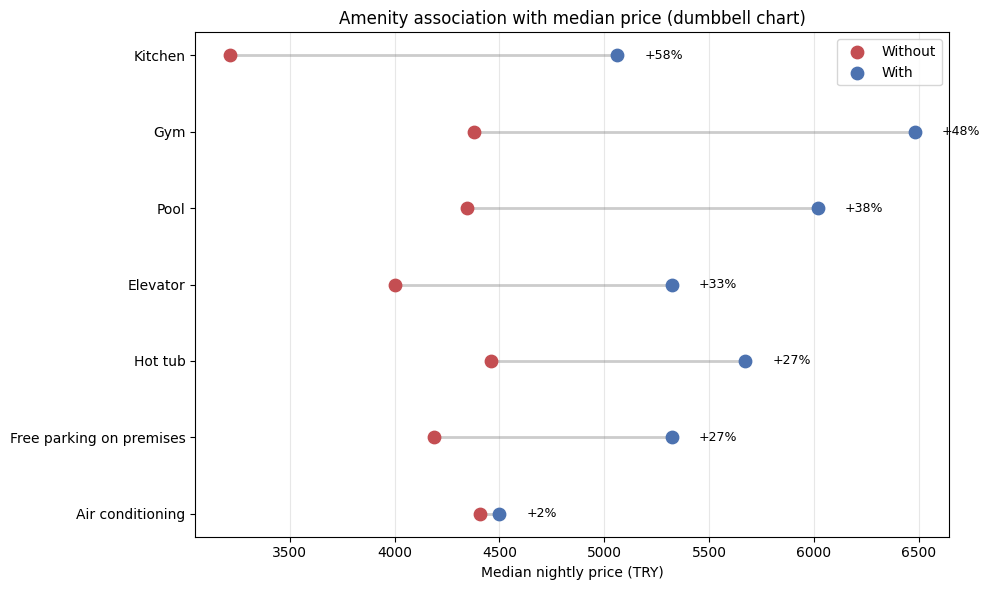

                 amenity  price_with  price_without  pct_diff  n_with
        Air conditioning    4,500.00       4,408.41      2.08   12170
Free parking on premises    5,322.50       4,188.00     27.09    4012
                 Hot tub    5,673.50       4,457.50     27.28     464
                Elevator    5,322.50       4,000.00     33.06    5633
                    Pool    6,018.91       4,347.00     38.46    1034
                     Gym    6,480.00       4,377.60     48.03     815
                 Kitchen    5,061.33       3,213.03     57.53   11950


In [37]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AMENITIES = [
    "Air conditioning", "Washing machine", "Kitchen",
    "Free parking on premises", "Pool", "Elevator",
    "Hot tub", "Gym",
]

parsed = df["amenities"].apply(
    lambda s: ast.literal_eval(s) if isinstance(s, str) else []
)

rows = []
min_listings = 10

for a in AMENITIES:
    has = parsed.apply(lambda lst: a in lst)
    n_with = int(has.sum())
    n_without = int((~has).sum())
    
    if n_with < min_listings or n_without < min_listings:
        continue
        
    with_price = df.loc[has, "price"].median()
    without_price = df.loc[~has, "price"].median()
    
    rows.append({
        "amenity": a,
        "price_with": with_price,       # renamed from "with"
        "price_without": without_price, # renamed from "without"
        "n_with": n_with,
        "n_without": n_without,
        "pct_diff": (with_price - without_price) / without_price * 100,
    })

amenity_df = (
    pd.DataFrame(rows)
    .dropna(subset=["price_with", "price_without"])
    .sort_values("pct_diff", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(amenity_df))

# Use the new column names
ax.hlines(y, amenity_df["price_without"], amenity_df["price_with"],
          color="gray", alpha=0.4, linewidth=2)

ax.scatter(amenity_df["price_without"], y, color="#C44E52", label="Without", s=80, zorder=3)
ax.scatter(amenity_df["price_with"], y, color="#4C72B0", label="With", s=80, zorder=3)

ax.set_yticks(y)
ax.set_yticklabels(amenity_df["amenity"])
ax.set_xlabel("Median nightly price (TRY)")
ax.set_title("Amenity association with median price (dumbbell chart)")
ax.legend()
ax.grid(axis="x", alpha=0.3)

# Now row.price_with and row.price_without are valid attributes
for i, row in enumerate(amenity_df.itertuples()):
    x_pos = max(row.price_with, row.price_without) + (amenity_df["price_with"].max() * 0.02)
    ax.text(x_pos, i, f"{row.pct_diff:+.0f}%", va="center", fontsize=9)

fig.tight_layout()
out_path = PROJECT_ROOT / "reports/eda/amenity_associations.png"
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_path, dpi=160, bbox_inches="tight")
plt.show()

print(amenity_df[["amenity", "price_with", "price_without", "pct_diff", "n_with"]].to_string(index=False))

In [38]:
import sys
from pathlib import Path
sys.path.append(str(Path("..").resolve() / "backend"))

from app.analytics.market_stats import (
    price_summary, neighborhood_summary, amenity_impact,
)

print(price_summary(df))
print(neighborhood_summary(df, top_n=5))
print(amenity_impact(df, ["Air conditioning", "Pool"]))

{'count': 16558, 'median': 4469.75, 'mean': 6321.835393163426, 'p25': 3000.0, 'p75': 6856.5675, 'p99': 38358.286200000046, 'min': 320.0, 'max': 502353.28}
                        median_price  mean_price  listings
neighbourhood_cleansed                                    
Silivri                    15,370.94   32,688.78        54
Beylikduzu                  7,372.50    9,508.76        58
Beykoz                      7,002.50    9,376.12        48
Sariyer                     6,800.00   13,101.74        70
Adalar                      6,688.00    7,959.61       151
            amenity  median_with  median_without  n_with  n_without  pct_diff
1              Pool     6,018.91        4,347.00    1034      15524     38.46
0  Air conditioning     4,500.00        4,408.41   12170       4388      2.08
